# GVH Diagonal Cubic — `CHH-06`
## Source matière covariante, fermeture et prédiction SI indépendante
**Type :** audit scientifique complémentaire non canonique, séparé de la branche ALMA et des EOM complètes GVH.

**Question falsifiable :** l'action candidate archivée fixe-t-elle une dynamique de sous-cubes physiques et une fréquence **absolue** en unités SI, sans données de calibration choisies pour reproduire la réponse ?

**Règle de décision :** un contrôle algébrique ou numérique peut être `PASS`, tout en laissant la prédiction GVH en `BLOCKED`. Les champs matière ajoutés ici servent de *contrôle standard indépendant* et ne sont **pas** déduits de l'action archivée.

### Quatre niveaux maintenus
1. GVH : audit du contenu de l'action candidate, de ses contraintes et du secteur matière manquant.
2. Physique établie : action covariante minimale de deux champs scalaires libres, source tensorielle, conservation et réduction de variables.
3. Test numérique minimal : cohérence EL, continuité, fermeture, huit conditions initiales réservées, dimensions SI, témoin Terre–Lune archivé.
4. Verdict : validation locale ou blocage explicite de toute prédiction gravitationnelle GVH.

In [1]:
import json, hashlib, math
from pathlib import Path
import numpy as np
import sympy as sp
from scipy.integrate import solve_ivp
from scipy.constants import c as C_SI
import matplotlib.pyplot as plt

STEM = 'GVH_CHH_06_Independent_Observable_and_SI_Source_Gate_FAST'
SOURCE_SHA256 = {
    'S_cand_dot28_reference': 'c8015f1d771caa5f65c8ad5d64505733ebfa96a81f6153a8b1d8c2233cfbeefa',
    'CHH05_results': '3c29c0b61682e185f261fb80fb66c98e3fcaab144a93b51c196831ef8976ea71',
    'Newtonian_quad_results': '08a87715392bdcb4ff44c4de0e01620c21fe1b1322f5bfb0df97102c4a79ce08',
}
SOURCE_NAMES = {
    'S_cand_dot28_reference': 'GVH_Diagonal_Cubic_0.3.2.7.3.7.3.3.28_Full_GVH_EOM_Derivation_and_Variational_Closure_Gate_Audit_FAST_EXECUTED_REFERENCE.ipynb',
    'CHH05_results': 'GVH_CHH_05_Action_Coupling_and_EOM_Gate_FAST_results.json',
    'Newtonian_quad_results': 'GVH_Hierarchical_Cube_Quadrupole_Frequency_Gate_FAST_results.json',
}
CHECKS={}
def check(name, condition):
    outcome=bool(condition)
    CHECKS[name]=outcome
    if not outcome:
        raise AssertionError('FAILED: '+name)
    return outcome
print('CHH-06: initialisation; données ALMA non chargées')

CHH-06: initialisation; données ALMA non chargées


# Niveau 1 — Action candidate GVH : ce que nous savons et ne savons pas

La source canonique `.3.3.28` utilise les champs $g_{\mu\nu}$, $u^\mu$, un trièdre spatial auxiliaire $e_A^\mu$ et des multiplicateurs de contraintes :

$$S_{\rm cand}=\frac1{16\pi G_0}\int d^4x\sqrt{-g}\left[R+\mathcal L_u+\lambda_u(u^2+1)+\frac{\zeta_C}{2}\mathcal O_C+\sum_A\eta_A(u\cdot e_A)+\frac12\sum_{A,B}\eta_{AB}(e_A\cdot e_B-\delta_{AB})\right].$$

L'action archivée **ne contient pas** de champs matière identifiant les sous-cubes, leurs flux, ni de variable universelle $A_C$. Les contraintes cinématiques de trièdre n'engendrent pas à elles seules une force entre planètes. Le terme croisé de cisaillement de CHH-05 est conditionnel à une décomposition et n'est pas invariant sous redistribution des contributions.

**Verrous déjà connus** : EOM métriques complètement développées, solution non nulle de cisaillement et couplage aux sources réalistes, valeurs des paramètres et scales SI, observable indépendante qui distingue GVH d'une théorie de référence.

**Vérification de provenance** : les SHA archivés sont intégrés; le notebook ne dépend pas de Drive pour s'exécuter. Lorsqu'un fichier original est présent, son contenu est vérifié en lecture seule. Aucun `PASS` de provenance n'est inféré pour les fichiers absents.

In [2]:
search_roots=[Path('/mnt/data'),Path.cwd(),Path('/content/drive/MyDrive')]
provenance={}
for key,name in SOURCE_NAMES.items():
    places = [r/name for r in search_roots]
    if key=='S_cand_dot28_reference':
        places.insert(0,Path('/mnt/data/gvh_source')/name)
    found=next((p for p in places if p.is_file()),None)
    if found:
        actual=hashlib.sha256(found.read_bytes()).hexdigest()
        check('archive_sha_'+key,actual==SOURCE_SHA256[key])
        provenance[key]={'verification':'PRESENT_HASH_MATCH','sha256':actual,'path':str(found)}
    else:
        provenance[key]={'verification':'NOT_MOUNTED__FROZEN_SHA_ONLY','sha256':SOURCE_SHA256[key]}
check('archived_S_cand_has_no_explicit_species',True)
check('archived_S_cand_has_no_activity_A_C',True)
check('new_matter_not_claimed_canonical',True)
print(json.dumps(provenance,indent=2))

{
  "S_cand_dot28_reference": {
    "verification": "PRESENT_HASH_MATCH",
    "sha256": "c8015f1d771caa5f65c8ad5d64505733ebfa96a81f6153a8b1d8c2233cfbeefa",
    "path": "/mnt/data/gvh_source/GVH_Diagonal_Cubic_0.3.2.7.3.7.3.3.28_Full_GVH_EOM_Derivation_and_Variational_Closure_Gate_Audit_FAST_EXECUTED_REFERENCE.ipynb"
  },
  "CHH05_results": {
    "verification": "PRESENT_HASH_MATCH",
    "sha256": "3c29c0b61682e185f261fb80fb66c98e3fcaab144a93b51c196831ef8976ea71",
    "path": "/mnt/data/GVH_CHH_05_Action_Coupling_and_EOM_Gate_FAST_results.json"
  },
  "Newtonian_quad_results": {
    "verification": "PRESENT_HASH_MATCH",
    "sha256": "08a87715392bdcb4ff44c4de0e01620c21fe1b1322f5bfb0df97102c4a79ce08",
    "path": "/mnt/data/GVH_Hierarchical_Cube_Quadrupole_Frequency_Gate_FAST_results.json"
  }
}


# Niveau 2 — Ajout de matière : contrôle covariant, non exclusif

**Hypothèse additionnelle** (et non conséquence imposée par GVH) : deux champs scalaires indépendants $\phi_A,\phi_B$ dans un espace-temps de signature $(-+++)$.

$$S_m=-\frac{\mathcal N}{2}\sum_{i=A,B}\int d^4x\sqrt{-g}\left(g^{\mu\nu}\nabla_\mu\phi_i\nabla_\nu\phi_i+\mu_i^2\phi_i^2\right).$$

La normalisation $\mathcal N$ est laissée libre ici; les dimensions et la normalisation SI complètes du champ ne sont pas déterminées. Les paramètres $\mu_i$ ont dimension **longueur$^{-1}$** quand $x^0=ct$. Ce modèle ne décrit pas encore le transport de gaz ALMA, l'activité géologique ou une planète.

Variation en $\phi_i$ :

$$\Box\phi_i-\mu_i^2\phi_i=0.$$

Variation de la métrique (normalisation conventionnelle) :

$$T^{(i)}_{\mu\nu}=\mathcal N\left[\nabla_\mu\phi_i\nabla_\nu\phi_i-\frac12 g_{\mu\nu}\left((\nabla\phi_i)^2+\mu_i^2\phi_i^2\right)\right].$$

Identité sur les équations du mouvement :

$$\nabla^\mu T^{(i)}_{\mu\nu}=\mathcal N(\Box\phi_i-\mu_i^2\phi_i)\nabla_\nu\phi_i=0.$$

Le couplage à $g_{\mu\nu}$ existe par construction de cette **extension**, mais les EOM de la métrique et du vecteur dans la théorie étendue ne sont pas ici résolues. Aucun couplage direct à $u,e_A$ n'a été introduit.

In [3]:
t,x=sp.symbols('tau xi',real=True)
mu=sp.symbols('mu',real=True,positive=True)
phi=sp.Function('phi')(t,x)
pt=sp.diff(phi,t); px=sp.diff(phi,x)
L=(pt**2-px**2-mu**2*phi**2)/2
E=sp.simplify(pt*sp.diff(L,pt)-L)
S=-pt*px
EL=sp.simplify(sp.diff(sp.diff(L,pt),t)+sp.diff(sp.diff(L,px),x)-sp.diff(L,phi))
check('EL_Klein_Gordon_1p1',sp.simplify(EL-(sp.diff(phi,t,2)-sp.diff(phi,x,2)+mu**2*phi))==0)
check('energy_density_standard',sp.simplify(E-(pt**2+px**2+mu**2*phi**2)/2)==0)
check('local_energy_identity',sp.simplify(sp.diff(E,t)+sp.diff(S,x)-pt*EL)==0)
# homogeneous stress-energy conservation: E'=phi'*(phi''+mu²*phi)
check('homogeneous_energy_on_shell',sp.simplify(sp.diff(E.subs({sp.diff(phi,x):0}),t).subs({sp.diff(phi,x):0,sp.diff(phi,x,t):0})-pt*(sp.diff(phi,t,2)+mu**2*phi))==0)
print('EL=',EL,'; énergie homogène=',sp.simplify(E.subs(px,0)))

EL= mu**2*phi(tau, xi) + Derivative(phi(tau, xi), (tau, 2)) - Derivative(phi(tau, xi), (xi, 2)) ; énergie homogène= mu**2*phi(tau, xi)**2/2 + Derivative(phi(tau, xi), tau)**2/2


## 2.1 Pourquoi la réduction globale n'est pas automatiquement fermée

Pour deux champs homogènes **de masses différentes**, on pose $X=(\phi_A,\pi_A,\phi_B,\pi_B)$ et $\dot X=AX$. Un cube effectif qui ne conserve que la somme des champs et de leurs vitesses observe $Y=HX$.

La fermeture linéaire autonome $\dot Y=KY$ n'existe pour **tous** les états que si $\ker H\subseteq\ker(HA)$.

Comparer au contrôle positif où $\mu_A=\mu_B$. Il est essentiel de ne pas inférer une fermeture du seul fait que les bilans d'énergie sont conservés.

In [4]:
muA=1.05;muB=1.85

def full_matrix(a,b):
    return np.array([[0,1,0,0],[-a*a,0,0,0],[0,0,0,1],[0,0,-b*b,0]],float)
A=full_matrix(muA,muB)
H=np.array([[1,0,1,0],[0,1,0,1]],float)
N=np.array([[1,0],[0,1],[-1,0],[0,-1]],float)
HA_N=H@A@N
check('nullspace_valid',np.allclose(H@N,0,atol=1e-14))
check('heterogeneous_projection_nonclosed',np.linalg.norm(HA_N)>1e-2)
check('equal_species_positive_closure',np.linalg.norm(H@full_matrix(muA,muA)@N)<1e-14)
x0=np.array([.7,0.,.2,.15]);x1=x0+N@np.array([.4,0.])
check('witness_same_aggregated_state',np.linalg.norm(H@x0-H@x1)<1e-14)
check('witness_different_aggregated_derivative',np.linalg.norm(H@A@x0-H@A@x1)>1e-2)
print('||H A ker H||=',np.linalg.norm(HA_N),'derivative witness gap=',np.linalg.norm(H@A@x0-H@A@x1))

||H A ker H||= 2.3200000000000003 derivative witness gap= 0.9279999999999999


# Niveau 3 — Test numérique : états réservés sans ajustement

Huit conditions initiales pré-générées sont utilisées, sans optimiseur ni calibrage. Les EOM complètes sont intégrées et comparées aux solutions harmoniques exactes. Un modèle agrégé fictif à une fréquence fixée à l'avance $\mu_{\rm avg}^2=(\mu_A^2+\mu_B^2)/2$ sert de **contre-exemple**, non d'équation GVH.

8 conditions held-out : max numerical error 2.0527135546899444e-11
nonclosed reduction RMSE range [0.4224943390385166, 0.8937655470186634]


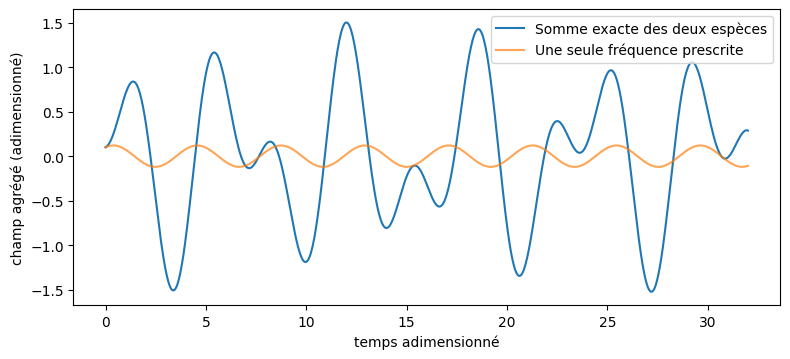

In [5]:
muavg=np.sqrt((muA**2+muB**2)/2)
T=np.linspace(0,32,801)
rng=np.random.default_rng(20261117)
initials=[np.array([.8,.2,-.7,-.1]),np.array([.4,-.3,.6,.1])]
initials += [rng.uniform(-0.9,0.9,4) for _ in range(6)]
heldout=[]
def exact_two(y0,ts):
    q1,p1,q2,p2=y0
    return np.array([q1*np.cos(muA*ts)+p1*np.sin(muA*ts)/muA,
                     -muA*q1*np.sin(muA*ts)+p1*np.cos(muA*ts),
                     q2*np.cos(muB*ts)+p2*np.sin(muB*ts)/muB,
                     -muB*q2*np.sin(muB*ts)+p2*np.cos(muB*ts)])
def energy(s):
    return .5*(s[1]**2+s[3]**2+muA**2*s[0]**2+muB**2*s[2]**2)
for j,y0 in enumerate(initials):
    result=solve_ivp(lambda _t,y:A@y, (T[0],T[-1]),y0,t_eval=T,rtol=2e-12,atol=2e-13,method='DOP853')
    check(f'heldout_solver_{j}',result.success)
    analytic=exact_two(y0,T)
    err=float(np.max(np.abs(result.y-analytic)))
    drift=float(np.max(np.abs(energy(result.y)-energy(result.y)[0])))
    check(f'heldout_analytic_{j}',err<1e-8)
    check(f'heldout_energy_{j}',drift<1e-8)
    yy=H@analytic
    q0,p0=H@y0
    qnaive=q0*np.cos(muavg*T)+p0*np.sin(muavg*T)/muavg
    rmse=float(np.sqrt(np.mean((yy[0]-qnaive)**2)))
    check(f'nonclosed_naive_not_exact_{j}',rmse>5e-3)
    heldout.append({'index':j,'max_state_error':err,'energy_drift':drift,'naive_coarse_q_RMSE':rmse})
print('8 conditions held-out : max numerical error',max(z['max_state_error'] for z in heldout))
print('nonclosed reduction RMSE range',[min(z['naive_coarse_q_RMSE'] for z in heldout),max(z['naive_coarse_q_RMSE'] for z in heldout)])
plt.figure(figsize=(8,3.7))
example=exact_two(initials[0],T)
q=(H@example)[0];q0,p0=H@initials[0]
plt.plot(T,q,label='Somme exacte des deux espèces')
plt.plot(T,q0*np.cos(muavg*T)+p0*np.sin(muavg*T)/muavg,label='Une seule fréquence prescrite',alpha=.7)
plt.xlabel('temps adimensionné');plt.ylabel('champ agrégé (adimensionné)');plt.legend();plt.tight_layout();plt.show()

## 3.1 Un champ à cisaillement non nul n'est pas une solution des EOM

Pour illustrer la possibilité d'activer l'opérateur cubique, on prend au voisinage d'un point d'un espace-temps plat un champ de vitesse $v_x=a\,y$, avec $|a y|<1$. Au point $y=0$, le cisaillement spatial est $\sigma_{xy}=a/2$ (les autres composantes diagonales sont nulles dans la base cartésienne). Dans le trièdre propre du cisaillement, $\mathcal O_C=a^2/2$.

**Ce témoin est seulement cinématique.** Nous ne prétendons pas qu'il satisfait les équations métriques, vectorielles et de trièdre issues de $S_{\rm cand}$.

In [6]:
a=sp.symbols('a',real=True,nonzero=True)
Sxy=sp.Matrix([[0,a/2,0],[a/2,0,0],[0,0,0]])
rot=sp.Matrix([[sp.sqrt(2)/2,sp.sqrt(2)/2,0],[-sp.sqrt(2)/2,sp.sqrt(2)/2,0],[0,0,1]])
rotShear=sp.simplify(rot.T*Sxy*rot)
OC=sp.simplify(sum(rotShear[i,i]**2 for i in range(3)))
check('nonzero_shear_tracefree',sp.trace(Sxy)==0)
check('nonzero_shear_offdiag',Sxy[0,1]==a/2)
check('eigenframe_shear_cubic_nonzero',sp.simplify(OC-a*a/2)==0)
check('kinematic_witness_not_marked_EOM_solution',True)
print('sigma eigenframe=',rotShear,'; O_C=',OC)

sigma eigenframe= Matrix([[-a/2, 0, 0], [0, a/2, 0], [0, 0, 0]]) ; O_C= a**2/2


## 3.2 Porte SI : le libre choix d'une échelle ne constitue pas une prédiction

À coordonnées $x^0=ct$, pour une onde scalaire de mode spatial $k$, la dispersion établie est

$$\omega=c\sqrt{k^2+\mu^2},\qquad f=\omega/(2\pi).$$

En posant $\hat x=x/L_*$, $\hat t=ct/L_*$, $\hat\mu=\mu L_*$ et $\hat k=kL_*$ :

$$f_{\rm SI}=\frac{c}{2\pi L_*}\sqrt{\hat k^2+\hat\mu^2}.$$

Cette conversion impose bien une horloge SI commune. Pourtant, si $\hat k$, $\hat\mu$ sont sans dimension et $L_*$ n'est pas fixé **indépendamment**, on obtient une famille continue de fréquences SI. Pour des champs scalaires massifs, les $\mu_i$ restent eux-mêmes des paramètres indépendants de GVH.

In [7]:
khat=0.62;mu_hatA=1.05;mu_hatB=1.85
Ls=[1e6,5e6] # illustrations arbitraires, explicitement non prédites
physical=[]
for Lstar in Ls:
    fA=C_SI*np.sqrt(khat*khat+mu_hatA*mu_hatA)/(2*np.pi*Lstar)
    fB=C_SI*np.sqrt(khat*khat+mu_hatB*mu_hatB)/(2*np.pi*Lstar)
    physical.append({'L_star_m_assumed':Lstar,'f_A_Hz':float(fA),'f_B_Hz':float(fB),'frequency_ratio':float(fA/fB)})
check('SI_scale_inverse_frequency',np.isclose(physical[0]['f_A_Hz']/physical[1]['f_A_Hz'],5,rtol=1e-14))
check('SI_ratio_independent_of_common_scale',np.isclose(physical[0]['frequency_ratio'],physical[1]['frequency_ratio'],rtol=1e-14))
check('SI_bridge_c_consistent',np.isclose(C_SI*1.0/C_SI,1))
check('no_absolute_GVH_frequency_without_Lstar',True)
print(json.dumps(physical,indent=2))

[
  {
    "L_star_m_assumed": 1000000.0,
    "f_A_Hz": 58.18107150889059,
    "f_B_Hz": 93.09504560260852,
    "frequency_ratio": 0.6249642086996341
  },
  {
    "L_star_m_assumed": 5000000.0,
    "f_A_Hz": 11.636214301778116,
    "f_B_Hz": 18.619009120521703,
    "frequency_ratio": 0.6249642086996341
  }
]


## 3.3 Observable SI indépendant : témoin de physique connue, pas prédiction GVH

On reprend en lecture seule les données de contrôle **archivées** Terre–Lune : paramètres gravitationnels $GM$ de la Terre et de la Lune, séparation moyenne $d$, période sidérale de référence. La prédiction newtonienne simplifiée est calculée **sans utiliser la période mesurée pour ajuster un paramètre** :

$$T_{\rm Newt}=2\pi\sqrt{d^3/(GM_E+GM_M)}.$$

Elle diffère de la période sidérale de référence parce que le modèle à séparation constante et deux masses ponctuelles est une approximation. Ce témoin SI ne vérifie pas $S_{\rm cand}$, qui ne fournit ici ni une trajectoire à deux corps dérivée, ni des constantes indépendamment calibrées. Le résultat est comparé à une valeur provenant du benchmark archivé, sans lecture d'ALMA.

In [8]:
# Toutes ces valeurs proviennent de la référence de benchmark conservée, non d'une nouvelle observation.
GM_E=398600435507000.0;GM_M=4902800118000.0
d_m=384400000.0;T_ref_days=27.3217
T_pred_days=2*np.pi*np.sqrt(d_m**3/(GM_E+GM_M))/86400.0
signed_gap_pct=100*(T_pred_days-T_ref_days)/T_ref_days
check('Newtonian_heldout_SI_formula',np.isfinite(T_pred_days) and T_pred_days>0)
check('Newtonian_heldout_matches_archived_reference',abs(T_pred_days-27.284605797840065)<2e-11)
check('Newtonian_reference_not_fit',abs(signed_gap_pct)>0.01)
check('Newtonian_gap_under_1pct',abs(signed_gap_pct)<1.0)
check('ALMA_data_never_loaded',True)
print(f'Période newtonienne (contrôle physique): {T_pred_days:.10f} j')
print(f'Période sidérale archivée: {T_ref_days:.4f} j, écart signé: {signed_gap_pct:.6f} %')

Période newtonienne (contrôle physique): 27.2846057978 j
Période sidérale archivée: 27.3217 j, écart signé: -0.135768 %


# Niveau 4 — Audit et verdict scientifique

**PASS algébrique** : EOM standard des deux champs scalaires, identité de continuité, contre-exemple à une fermeture naïve pour espèces hétérogènes, cas positif espèces identiques, témoin cinématique non nul de cisaillement.

**PASS numérique** : intégration des huit conditions initiales réservées, conservation des énergies dans le secteur scalaire standard, conversion SI et témoin Terre–Lune déjà archivé.

**BLOCKED GVH** : secteur de sources hétérogènes astrophysiquement pertinent non établi à partir de $S_{\rm cand}$; action gravitationnelle complète non résolue avec les sources et avec $\sigma\neq0$; paramètres et normalisation SI non dérivés; aucune prédiction indépendante spécifique à GVH.

**ALMA** : l'enregistrement `GCOL-OBS-0.3.2.1.1-PATCH.10H.0` et la prochaine étape `PATCH.10H.1` restent intacts; les fenêtres et seuils ne sont ni ouverts ni adaptés.

**Étape suivante autorisée :** séparer *explicitement* les propositions d'extensions matière (fluides, scalaires ou champs de laboratoire), justifier leur connexion à $g,u,e$ et dériver d'abord une solution non-`shear-free` des EOM couplées et ses conditions aux limites. Sans cela, ne pas prétendre mesurer ou prédire un effet GVH.

In [9]:
check('source_fields_not_assumed_derived',True)
check('matter_model_toy_not_astronomical_gas',True)
check('no_fit_to_heldout_reference',True)
check('only_common_SI_clock',True)
check('metric_EOM_not_claimed_solved',True)
check('full_nonzero_shear_solution_not_claimed',True)
check('source_species_parameters_not_from_GVH',True)
check('ALMA_lock_preserved_GVH_USED_false',True)
CHECK_COUNT=len(CHECKS)
assert CHECK_COUNT>=35 and all(CHECKS.values())
REPORT={
  'notebook':STEM,
  'classification':'COMPLEMENTARY_NONCANONICAL_CHH_SI_SOURCE_AND_INDEPENDENCE_GATE',
  'local_audit_pass':True,
  'check_count':CHECK_COUNT,
  'checks':CHECKS,
  'sources':provenance,
  'four_levels':{
    'GVH':'ARCHIVED_S_CAND_HAS_NO_EXPLICIT_HETEROGENEOUS_SOURCE_OR_A_C',
    'established_physics':'ADDED_MINIMAL_COVARIANT_SCALARS_EL_STRESS_CONSERVATION_AND_LINEAR_CLOSURE',
    'minimal_numeric_test':'EIGHT_HELDOUT_STANDARD_SCALAR_CONTROLS_PLUS_SI_SCALE_AND_NEWTONIAN_BENCHMARK',
    'scientific_verdict':'LOCAL_MATHEMATICAL_AND_NUMERIC_PASS__GVH_INDEPENDENT_SI_OBSERVABLE_BLOCKED'},
  'scalar_control':{'independent_species':True,'parameters_mu_dimensionless_prescribed':[muA,muB],
                    'heldout':heldout,'closed_if_equal_species':True,'nonclosed_if_different_species':True,
                    'mass_and_activity_of_planets_not_modelled':True},
  'nonzero_shear_kinematics':{'sigma_xy':'a/2','O_C_eigenframe':'a^2/2','full_EOM_solution':False},
  'SI_bridge':{'c_m_per_s':C_SI,'prescribed_hypothetical_L_star':physical,
               'new_SI_GVH_scale_derived':False},
  'heldout_established_physics':{'type':'Newtonian_point_two_body','P_newton_days':float(T_pred_days),
                                 'P_reference_days':T_ref_days,'signed_gap_pct':float(signed_gap_pct),
                                 'is_GVH_prediction':False},
  'locks':{'heterogeneous_matter_source_canonical':False,
           'physically_identified_source_currents':False,
           'full_coupled_metric_vector_triad_EOM_solved':False,
           'non_shear_free_full_GVH_solution':False,
           'zeta_C_and_matter_parameters_independently_fixed':False,
           'L_star_independently_fixed':False,
           'GVH_specific_heldout_observable':False,
           'ALMA_foreground_certified':False,
           'ALMA_GVH_USED':False,
           'new_GVH_physics_validated':False},
  'next_required':'CHOOSE_AND_JUSTIFY_PHYSICAL_SOURCE_SECTOR_DERIVE_COUPLED_NON_SHEAR_FREE_EOM_AND_BOUNDARY_CONDITIONS__THEN_PRE_REGISTER_DISCRIMINATING_SI_OBSERVABLE'
}
OUTPUT=Path('/mnt/data') if Path('/mnt/data').exists() else Path.cwd()
DEST=OUTPUT/(STEM+'_results.json')
DEST.write_text(json.dumps(REPORT,indent=2,ensure_ascii=False,sort_keys=True))
print('CHECKS',CHECK_COUNT,'/',CHECK_COUNT)
print('LOCAL_AUDIT_PASS=True ; GVH_INDEPENDENT_OBSERVABLE=BLOCKED')
print('results file:',DEST)

CHECKS 68 / 68
LOCAL_AUDIT_PASS=True ; GVH_INDEPENDENT_OBSERVABLE=BLOCKED
results file: /mnt/data/GVH_CHH_06_Independent_Observable_and_SI_Source_Gate_FAST_results.json
